# FMEA and FMEDA for Perception Hardware and Software

**Module 03 · Functional Safety (ISO 26262)** · Notebook 3 of 6

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/milinpatel07/Autonomous-Driving_AI-Safety-and-Security/blob/main/03_Functional_Safety_ISO26262/03_fmea_and_fmeda.ipynb) [![Run in browser](https://img.shields.io/badge/Run_in_browser-no_account-0072B2)](https://milinpatel07.github.io/Autonomous-Driving_AI-Safety-and-Security/lite/notebooks/index.html?path=03_Functional_Safety_ISO26262/03_fmea_and_fmeda.ipynb)

| Level | Prerequisites | Standards |
|---|---|---|
| Intermediate | [02 HARA](02_hara.ipynb) | ISO 26262-5:2018, ISO 26262-9:2018, AIAG & VDA FMEA Handbook (2019) |

**Author:** Milin Patel · Hochschule Kempten · MIT Licence

## Learning objectives

By the end of this notebook you will be able to:

1. Place FMEA and FMEDA within ISO 26262 (inductive safety analysis; hardware metrics)
2. Build a design FMEA for a camera perception channel and trace failure effects to the HARA safety goals
3. Explain the pitfalls of the Risk Priority Number and apply the AIAG-VDA Action Priority (AP) lookup
4. Compute SPFM, LFM and a first-order PMHF estimate from an FMEDA, including latent-fault coverage
5. Recognise which perception 'failure modes' are really SOTIF / ISO/PAS 8800 insufficiencies

## 1. FMEA fundamentals

ISO 26262 does **not** define the FMEA method. It requires **safety analyses**: inductive (bottom-up) and deductive (top-down) analyses whose rigour depends on the ASIL (ISO 26262-9:2018, clause 8, applied in ISO 26262-4, -5 and -6). FMEA is the most common *inductive* method; fault tree analysis is the most common *deductive* one (see [Notebook 04](04_fault_tree_analysis.ipynb)). The method itself is defined in the **AIAG & VDA FMEA Handbook (2019)**, **SAE J1739:2021** and **IEC 60812:2018**.

### Types of FMEA used in automotive practice

| Type | Focus | Role in ISO 26262 |
|---|---|---|
| **DFMEA** (design) | Failure modes of system, hardware or software design elements | Accepted inductive safety analysis (ISO 26262-9, clause 8) |
| **PFMEA** (process) | Manufacturing and assembly process failures | Quality tool under IATF 16949, not an ISO 26262 work product (production is covered by ISO 26262-7) |
| **FMEDA** (failure modes, effects and diagnostic analysis) | Hardware failure rates, failure-mode distribution and diagnostic coverage | Provides the hardware architectural metrics and PMHF inputs of ISO 26262-5 |

### AIAG-VDA seven-step approach (2019)

```
1 Planning & preparation -> 2 Structure analysis -> 3 Function analysis -> 4 Failure analysis
-> 5 Risk analysis (S, O, D -> Action Priority) -> 6 Optimisation -> 7 Results documentation
```

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass, field
from typing import List, Dict, Optional
from IPython.display import display

rng = np.random.default_rng(42)
plt.rcParams.update({"figure.dpi": 100})
print("FMEA analysis tools loaded.")

FMEA analysis tools loaded.


## 2. FMEA rating scales

FMEA ratings run from 1 to 10. The scales below are **abridged paraphrases of the design-FMEA criteria of the AIAG FMEA Reference Manual, 4th edition (2008)**. The AIAG & VDA Handbook (2019) uses reworded tables, and rates design-FMEA occurrence from the effectiveness of *prevention controls* rather than from failure counts. Use the full tables of the handbook your organisation has adopted. FMEA severity is **not** an ISO 26262 S class, and it says nothing about the ASIL, which depends on S, E and C together.

In [2]:
# Abridged from AIAG FMEA 4th ed. (2008), DFMEA criteria (paraphrased)
SEVERITY_SCALE = {
    10: "Affects safe vehicle operation and/or non-compliance with regulation, without warning",
    9: "Affects safe vehicle operation and/or non-compliance with regulation, with warning",
    8: "Loss of primary function (vehicle inoperable, safe operation not affected)",
    7: "Degradation of primary function (vehicle operable at reduced performance)",
    6: "Loss of secondary (comfort/convenience) function",
    5: "Degradation of secondary function",
    4: "Annoyance: noticed by most customers (> 75 %)",
    3: "Annoyance: noticed by many customers (about 50 %)",
    2: "Annoyance: noticed by discriminating customers (< 25 %)",
    1: "No discernible effect",
}
# Incidents per 1000 items/vehicles (AIAG 4th ed. DFMEA occurrence)
OCCURRENCE_SCALE = {
    10: ">= 100 per 1000", 9: "50 per 1000", 8: "20 per 1000", 7: "10 per 1000", 6: "2 per 1000",
    5: "0.5 per 1000", 4: "0.1 per 1000", 3: "0.01 per 1000", 2: "<= 0.001 per 1000",
    1: "Failure eliminated through preventive control",
}
DETECTION_SCALE = {  # likelihood that design controls detect the cause/failure mode before release
    10: "Absolute uncertainty: no design control, or not analysed",
    9: "Very remote: analysis with weak detection capability",
    8: "Remote: pass/fail product testing after design freeze",
    7: "Very low: test-to-failure after design freeze",
    6: "Low: degradation testing after design freeze",
    5: "Moderate: pass/fail testing before design freeze",
    4: "Moderately high: test-to-failure before design freeze",
    3: "High: degradation testing before design freeze",
    2: "Very high: correlated virtual analysis/simulation before design freeze",
    1: "Almost certain: failure cause prevented by design (e.g. proven standard)",
}


def display_scale(scale: dict, title: str):
    print(f"\n{title}")
    print("=" * 70)
    for k in sorted(scale, reverse=True):
        print(f"{k:2d}: {scale[k]}")

display_scale(SEVERITY_SCALE, "Severity (S)")
display_scale(OCCURRENCE_SCALE, "Occurrence (O)")
display_scale(DETECTION_SCALE, "Detection (D)")


Severity (S)
10: Affects safe vehicle operation and/or non-compliance with regulation, without warning
 9: Affects safe vehicle operation and/or non-compliance with regulation, with warning
 8: Loss of primary function (vehicle inoperable, safe operation not affected)
 7: Degradation of primary function (vehicle operable at reduced performance)
 6: Loss of secondary (comfort/convenience) function
 5: Degradation of secondary function
 4: Annoyance: noticed by most customers (> 75 %)
 3: Annoyance: noticed by many customers (about 50 %)
 2: Annoyance: noticed by discriminating customers (< 25 %)
 1: No discernible effect

Occurrence (O)
10: >= 100 per 1000
 9: 50 per 1000
 8: 20 per 1000
 7: 10 per 1000
 6: 2 per 1000
 5: 0.5 per 1000
 4: 0.1 per 1000
 3: 0.01 per 1000
 2: <= 0.001 per 1000
 1: Failure eliminated through preventive control

Detection (D)
10: Absolute uncertainty: no design control, or not analysed
 9: Very remote: analysis with weak detection capability
 8: Remote: pas

## 3. FMEA data structure and Action Priority

Two ways to prioritise actions:

- **Risk Priority Number**: RPN = S × O × D (1 to 1000). Simple, but problematic (section 6).
- **Action Priority (AP)**: introduced by the AIAG & VDA FMEA Handbook (2019) and permitted by SAE J1739:2021. A lookup table assigns **H** (high), **M** (medium) or **L** (low) priority and weights severity first, then occurrence, then detection.

The AP function below implements the AIAG-VDA table as reproduced by [Relyence (FMEA AP help page)](https://relyence.com/help/user-guide/fmea-ap.html), which matches the author's copy of the table. Verify it against the handbook before using it in a project.

FMECA's *criticality* (S × O, IEC 60812 / MIL-STD-1629A) is shown as well; it is not an ISO 26262 quantity.

In [3]:
def action_priority(s: int, o: int, d: int) -> str:
    """AIAG & VDA FMEA Handbook (2019) Action Priority for DFMEA/PFMEA: 'H', 'M' or 'L'."""
    for name, v in (("S", s), ("O", o), ("D", d)):
        if not (isinstance(v, (int, np.integer)) and 1 <= v <= 10):
            raise ValueError(f"{name} must be an integer 1..10, got {v!r}")
    if s == 1:
        return "L"
    if s <= 3:
        return "M" if (o >= 8 and d >= 5) else "L"
    if s <= 6:
        if o >= 8:
            return "H" if d >= 5 else "M"
        if o >= 6:
            return "M" if d >= 2 else "L"
        if o >= 4:
            return "M" if d >= 7 else "L"
        return "L"
    if s <= 8:
        if o >= 8:
            return "H"
        if o >= 6:
            return "H" if d >= 2 else "M"
        if o >= 4:
            return "H" if d >= 7 else "M"
        if o >= 2:
            return "M" if d >= 5 else "L"
        return "L"
    # s = 9..10
    if o >= 6:
        return "H"
    if o >= 4:
        return "H" if d >= 2 else "M"
    if o >= 2:
        return "H" if d >= 7 else ("M" if d >= 5 else "L")
    return "L"

AP_RANK = {"H": 2, "M": 1, "L": 0}


@dataclass
class FailureMode:
    """One row of a design FMEA."""
    id: str
    component: str
    function: str
    failure_mode: str
    failure_effect_local: str
    failure_effect_system: str
    severity: int          # 1-10
    failure_cause: str
    occurrence: int        # 1-10
    current_controls: str
    detection: int         # 1-10
    domain: str = "ISO 26262"       # or "ISO 21448 / ISO/PAS 8800" for performance insufficiencies
    safety_goal: str = ""           # trace of the effect to a HARA safety goal
    recommended_actions: str = ""
    new_severity: Optional[int] = None
    new_occurrence: Optional[int] = None
    new_detection: Optional[int] = None

    @property
    def rpn(self) -> int:
        return self.severity * self.occurrence * self.detection

    @property
    def ap(self) -> str:
        return action_priority(self.severity, self.occurrence, self.detection)

    @property
    def new_rpn(self) -> Optional[int]:
        vals = (self.new_severity, self.new_occurrence, self.new_detection)
        return None if any(v is None for v in vals) else int(np.prod(vals))

    @property
    def criticality(self) -> int:
        """Criticality index S x O (FMECA practice, IEC 60812 / MIL-STD-1629A; not defined in ISO 26262)."""
        return self.severity * self.occurrence

In [4]:
@dataclass
class FMEAWorksheet:
    """FMEA worksheet."""
    system_name: str
    subsystem: str
    prepared_by: str
    fmea_date: str
    revision: str
    failure_modes: List[FailureMode] = field(default_factory=list)

    def add_failure_mode(self, fm: FailureMode):
        self.failure_modes.append(fm)

    def above_rpn(self, threshold: int = 100) -> List[FailureMode]:
        """Failure modes with RPN >= threshold, sorted by RPN (descending)."""
        return sorted((f for f in self.failure_modes if f.rpn >= threshold), key=lambda f: f.rpn, reverse=True)

    def high_severity(self, threshold: int = 9) -> List[FailureMode]:
        return [f for f in self.failure_modes if f.severity >= threshold]

    def to_dataframe(self) -> pd.DataFrame:
        return pd.DataFrame([{
            "ID": f.id, "Component": f.component, "Failure mode": f.failure_mode,
            "System effect": f.failure_effect_system, "S": f.severity, "Cause": f.failure_cause,
            "O": f.occurrence, "Controls": f.current_controls, "D": f.detection, "RPN": f.rpn,
            "AP": f.ap if f.domain == "ISO 26262" else "n/a", "Domain": f.domain, "Safety goal": f.safety_goal,
            "S x O": f.criticality} for f in self.failure_modes])

    def summary_statistics(self) -> Dict:
        ee = [f for f in self.failure_modes if f.domain == "ISO 26262"]
        return {"total_failure_modes": len(self.failure_modes), "ee_failure_modes": len(ee),
                "max_rpn": max((f.rpn for f in self.failure_modes), default=0),
                "ap_counts": pd.Series([f.ap for f in ee]).value_counts().to_dict(),
                "high_severity_count": len(self.high_severity())}

## 4. DFMEA example: forward camera channel of the AEB function

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

The effects are traced to the safety goals of the AEB HARA in [Notebook 02](02_hara.ipynb): **SG-01** "Avoid unintended AEB deceleration" [ASIL D] and **SG-02** "Avoid omission of AEB deceleration when a collision is imminent" [ASIL B].

> **ML "failure modes" are a different kind of thing.** Misclassification, missed detection or phantom detection of a correctly working neural network are **performance insufficiencies**. They do not arise from random faults with a failure rate, so an "occurrence" rating for them is not a probability of hardware or software failure. They are listed below for contrast, marked *ISO 21448 / ISO/PAS 8800*, and analysed with triggering-condition analysis and statistical validation (Modules 04 and 06). Lens obstruction by dirt or ice is an environmental triggering condition and is treated the same way. See also Patel and Jung (2026, VEHITS) on using uncertainty evaluation to identify such performance insufficiencies.

In [5]:
camera_fmea = FMEAWorksheet(system_name="AEB function", subsystem="Forward camera channel",
                            prepared_by="Safety engineering (teaching example)", fmea_date="2026-10", revision="2.0")

SOTIF = "ISO 21448 / ISO/PAS 8800"
camera_failure_modes = [
    FailureMode("CAM-001", "Image sensor", "Capture the scene", "Complete image loss",
                "No image data", "AEB cannot act; frame-loss detected, AEB unavailable warning", 9,
                "Sensor hardware failure, power loss", 2, "Frame-loss monitor, power monitoring", 2,
                safety_goal="SG-02", recommended_actions="Verify frame-loss FDTI against FTTI"),
    FailureMode("CAM-002", "Image sensor", "Capture the scene", "Degraded image (noise, blur) from hardware ageing",
                "Reduced image quality", "Missed or ghost objects: AEB omission or unintended braking", 9,
                "Pixel ageing, temperature drift, vibration", 4, "Image-quality monitor", 4,
                safety_goal="SG-01, SG-02", recommended_actions="Thermal design margin; built-in self-test of the image pipeline"),
    FailureMode("CAM-003", "Lens assembly", "Focus light onto sensor", "Lens obstruction (dirt, ice, debris)",
                "Partial or full blockage", "Blind regions, missed objects", 8,
                "Environmental contamination (triggering condition)", 5, "Blockage-detection algorithm", 3,
                domain=SOTIF, recommended_actions="Treat in SOTIF analysis; lens heating/cleaning"),
    FailureMode("CAM-004", "Neural network", "Detect and classify objects", "Misclassification",
                "Wrong class label", "Wrong threat assessment", 8,
                "Training-data gaps, out-of-distribution inputs", 4, "Confidence thresholding", 5,
                domain=SOTIF, recommended_actions="Uncertainty estimation, OOD monitoring (Module 06)"),
    FailureMode("CAM-005", "Neural network", "Detect and classify objects", "False negative (missed detection)",
                "Object not reported", "AEB omission", 10,
                "Low contrast, occlusion, unusual appearance", 3, "Multi-sensor fusion", 4,
                domain=SOTIF, recommended_actions="Data coverage, scenario-based validation"),
    FailureMode("CAM-006", "Neural network", "Detect and classify objects", "False positive (phantom detection)",
                "Non-existent object reported", "Unintended AEB braking", 7,
                "Reflections, shadows, visual artefacts", 4, "Temporal consistency check", 3,
                domain=SOTIF, recommended_actions="Radar cross-check, multi-frame validation"),
    FailureMode("CAM-007", "Processing unit", "Execute perception software", "Processing deadline exceeded",
                "Delayed object list", "Stale data: late or unintended braking", 9,
                "Thermal throttling, task overrun after hardware fault", 3, "Watchdog, deadline monitor", 2,
                safety_goal="SG-01, SG-02", recommended_actions="Check FDTI + FRTI <= FTTI"),
    FailureMode("CAM-008", "Calibration data", "Map pixels to vehicle coordinates", "Calibration parameters corrupted or drifted",
                "Wrong spatial measurement", "Distance errors: late or unintended braking", 9,
                "Memory corruption, mounting shift after mechanical shock", 3, "Periodic calibration check", 5,
                safety_goal="SG-01, SG-02", recommended_actions="CRC on calibration data; online self-calibration"),
]
for fm in camera_failure_modes:
    camera_fmea.add_failure_mode(fm)
print(f"Created FMEA with {len(camera_fmea.failure_modes)} rows "
      f"({sum(f.domain == 'ISO 26262' for f in camera_fmea.failure_modes)} ISO 26262 failure modes).")

Created FMEA with 8 rows (4 ISO 26262 failure modes).


In [6]:
df = camera_fmea.to_dataframe()
cols = ["ID", "Component", "Failure mode", "S", "O", "D", "RPN", "AP", "Domain", "Safety goal"]
print("Camera channel DFMEA, sorted by RPN")
print("=" * 100)
print(df[cols].sort_values("RPN", ascending=False).to_string(index=False))

Camera channel DFMEA, sorted by RPN
     ID        Component                                      Failure mode  S  O  D  RPN  AP                   Domain  Safety goal
CAM-004   Neural network                                 Misclassification  8  4  5  160 n/a ISO 21448 / ISO/PAS 8800             
CAM-002     Image sensor Degraded image (noise, blur) from hardware ageing  9  4  4  144   H                ISO 26262 SG-01, SG-02
CAM-008 Calibration data       Calibration parameters corrupted or drifted  9  3  5  135   M                ISO 26262 SG-01, SG-02
CAM-003    Lens assembly              Lens obstruction (dirt, ice, debris)  8  5  3  120 n/a ISO 21448 / ISO/PAS 8800             
CAM-005   Neural network                 False negative (missed detection) 10  3  4  120 n/a ISO 21448 / ISO/PAS 8800             
CAM-006   Neural network                False positive (phantom detection)  7  4  3   84 n/a ISO 21448 / ISO/PAS 8800             
CAM-007  Processing unit                      P

## 5. RPN analysis and visualisation

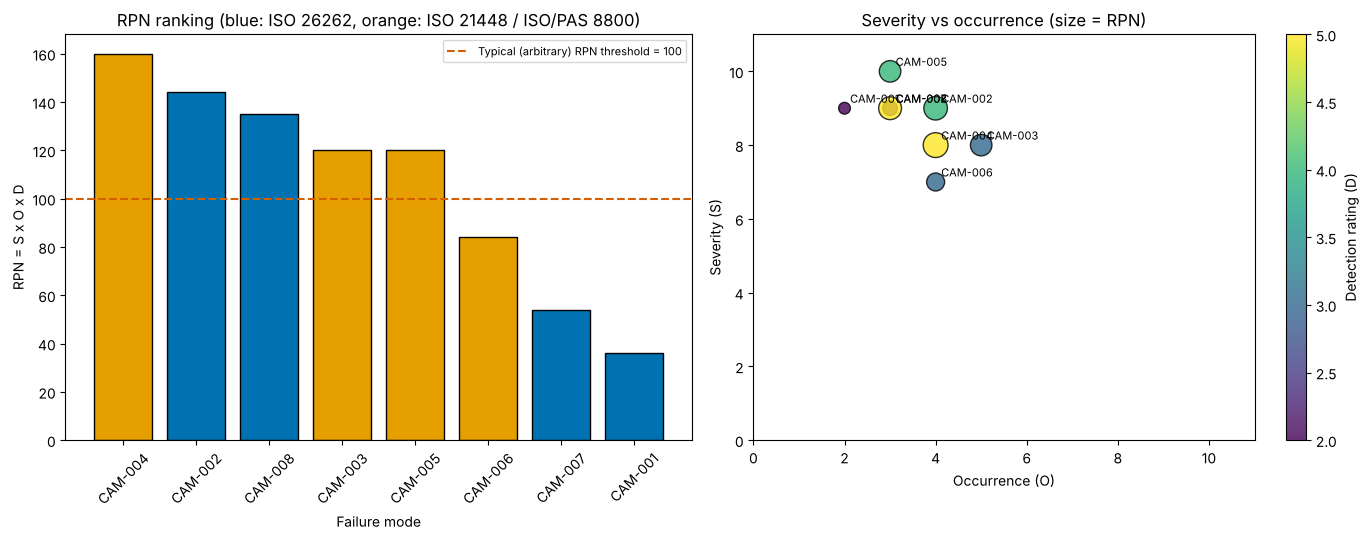

--- RPN analysis (text summary) ---
  CAM-004: RPN 160 (S8/O4/D5), ISO 21448 / ISO/PAS 8800
  CAM-002: RPN 144 (S9/O4/D4), ISO 26262
  CAM-008: RPN 135 (S9/O3/D5), ISO 26262
  CAM-003: RPN 120 (S8/O5/D3), ISO 21448 / ISO/PAS 8800
  CAM-005: RPN 120 (S10/O3/D4), ISO 21448 / ISO/PAS 8800
  CAM-006: RPN 84 (S7/O4/D3), ISO 21448 / ISO/PAS 8800
  CAM-007: RPN 54 (S9/O3/D2), ISO 26262
  CAM-001: RPN 36 (S9/O2/D2), ISO 26262


In [7]:
def plot_rpn_analysis(fmea: FMEAWorksheet):
    df = fmea.to_dataframe()
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    # 1. RPN ranking, coloured by domain
    d = df.sort_values("RPN", ascending=False)
    colours = ["#0072B2" if dom == "ISO 26262" else "#E69F00" for dom in d["Domain"]]
    axes[0].bar(d["ID"], d["RPN"], color=colours, edgecolor="black")
    axes[0].axhline(100, color="#D55E00", ls="--", label="Typical (arbitrary) RPN threshold = 100")
    axes[0].set_ylabel("RPN = S x O x D"); axes[0].set_xlabel("Failure mode")
    axes[0].set_title("RPN ranking (blue: ISO 26262, orange: ISO 21448 / ISO/PAS 8800)")
    axes[0].tick_params(axis="x", rotation=45); axes[0].legend(fontsize=8)
    # 2. Severity vs occurrence, marker size = RPN
    sc = axes[1].scatter(df["O"], df["S"], s=df["RPN"] * 2, c=df["D"], cmap="viridis", alpha=0.8, edgecolor="black")
    for _, r in df.iterrows():
        axes[1].annotate(r["ID"], (r["O"], r["S"]), fontsize=8, xytext=(4, 4), textcoords="offset points")
    axes[1].set_xlim(0, 11); axes[1].set_ylim(0, 11)
    axes[1].set_xlabel("Occurrence (O)"); axes[1].set_ylabel("Severity (S)")
    axes[1].set_title("Severity vs occurrence (size = RPN)")
    plt.colorbar(sc, ax=axes[1], label="Detection rating (D)")
    plt.tight_layout(); plt.show()
    return df

df = plot_rpn_analysis(camera_fmea)
print("--- RPN analysis (text summary) ---")
for _, r in df.sort_values("RPN", ascending=False).iterrows():
    print(f"  {r.ID}: RPN {r.RPN} (S{r.S}/O{r.O}/D{r.D}), {r.Domain}")

## 6. From RPN to Action Priority

**Pitfalls of the RPN** (the reasons the AIAG & VDA Handbook replaced it):

1. **The ordinal scales are multiplied as if they were ratios.** S = 10 is not "twice as bad" as S = 5.
2. **Identical RPNs hide very different risks**: S9 · O5 · D2 = 90 and S3 · O6 · D5 = 90.
3. **Only 120 of the 1000 S·O·D combinations give distinct RPN values**, and they cluster at the low end.
4. **Thresholds are arbitrary.** A rule such as "act if RPN ≥ 100" can drop a high-severity failure mode with poor prevention.
5. **Detection counts as much as prevention**, although a detected design flaw is still a design flaw.

The **Action Priority** table addresses points 2–5 by ranking severity first, then occurrence, then detection.

Distinct RPN values among 1000 combinations: 120
  S9 O5 D2: RPN  90, AP H, misses an RPN >= 100 threshold
  S3 O6 D5: RPN  90, AP L, misses an RPN >= 100 threshold


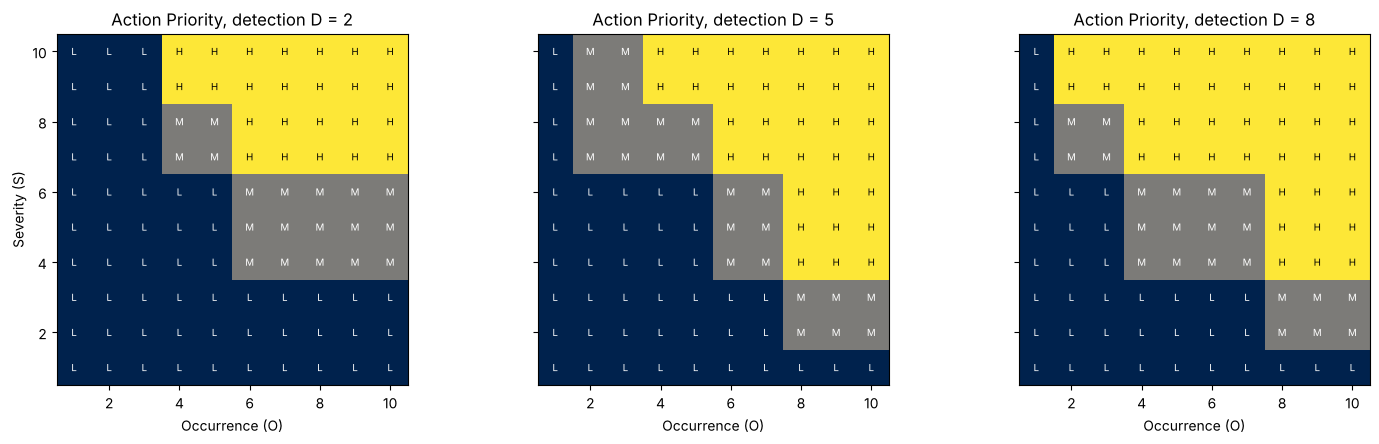

--- AP grid (text summary) ---
  D = 2: 24 of 100 (S, O) cells are H
  D = 5: 33 of 100 (S, O) cells are H
  D = 8: 41 of 100 (S, O) cells are H

ISO 26262 failure modes, ranked by AP, then S, then RPN:
  CAM-002: AP H, S9 O4 D4, RPN 144
  CAM-008: AP M, S9 O3 D5, RPN 135
  CAM-007: AP L, S9 O3 D2, RPN 54  <- below RPN 100 but S >= 9: review anyway
  CAM-001: AP L, S9 O2 D2, RPN 36  <- below RPN 100 but S >= 9: review anyway


In [8]:
# Pitfall 3: distinct RPN values
rpns = {s * o * d for s in range(1, 11) for o in range(1, 11) for d in range(1, 11)}
print(f"Distinct RPN values among 1000 combinations: {len(rpns)}")

# Pitfall 2 and 4: same RPN, different priority; threshold misses
pairs = [(9, 5, 2), (3, 6, 5)]
for s, o, d in pairs:
    print(f"  S{s} O{o} D{d}: RPN {s * o * d:3d}, AP {action_priority(s, o, d)}, "
          f"{'passes' if s * o * d >= 100 else 'misses'} an RPN >= 100 threshold")

# AP grid for three detection ratings
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
for ax, d in zip(axes, [2, 5, 8]):
    grid = np.array([[AP_RANK[action_priority(s, o, d)] for o in range(1, 11)] for s in range(1, 11)])
    ax.imshow(grid, origin="lower", cmap="cividis", vmin=0, vmax=2, extent=(0.5, 10.5, 0.5, 10.5))
    for s in range(1, 11):
        for o in range(1, 11):
            lab = action_priority(s, o, d)
            ax.text(o, s, lab, ha="center", va="center", fontsize=7, color="black" if lab == "H" else "white")
    ax.set_title(f"Action Priority, detection D = {d}"); ax.set_xlabel("Occurrence (O)")
axes[0].set_ylabel("Severity (S)")
plt.tight_layout(); plt.show()

print("--- AP grid (text summary) ---")
for d in [2, 5, 8]:
    n_h = sum(action_priority(s, o, d) == "H" for s in range(1, 11) for o in range(1, 11))
    print(f"  D = {d}: {n_h} of 100 (S, O) cells are H")

# Apply to the ISO 26262 rows of the camera FMEA
ee = [f for f in camera_fmea.failure_modes if f.domain == "ISO 26262"]
print("\nISO 26262 failure modes, ranked by AP, then S, then RPN:")
for f in sorted(ee, key=lambda f: (AP_RANK[f.ap], f.severity, f.rpn), reverse=True):
    flag = "  <- below RPN 100 but S >= 9: review anyway" if f.rpn < 100 and f.severity >= 9 else ""
    print(f"  {f.id}: AP {f.ap}, S{f.severity} O{f.occurrence} D{f.detection}, RPN {f.rpn}{flag}")

## 7. Linking FMEA to the safety concept

Do **not** convert FMEA severity into a HARA S class: the two scales measure different things, and the ASIL comes only from the HARA. Instead, **trace** each failure effect to the safety goal it could violate, and take the ASIL from that goal. The safety mechanisms that the FMEA identifies feed into the technical safety concept and must meet the timing (FTTI) and diagnostic-coverage claims used in the FMEDA.

In [9]:
SAFETY_GOALS = {"SG-01": ("Avoid unintended AEB deceleration", "D"),
                "SG-02": ("Avoid omission of AEB deceleration when a collision is imminent", "B")}


def suggest_safety_mechanisms(fm: FailureMode) -> List[str]:
    """Heuristic suggestions (teaching aid, not a rule set)."""
    if fm.domain != "ISO 26262":
        return ["Analyse as a performance insufficiency (triggering conditions, data coverage, runtime monitoring)"]
    out = []
    if fm.severity >= 9:
        out.append("Diagnostic with defined FDTI and transition to the safe state of the traced safety goal")
    if fm.occurrence >= 4:
        out.append("Prevention: design margin, derating, robust components (lowers O, which AP rewards)")
    if fm.detection >= 5:
        out.append("Stronger design verification before design freeze (lowers D)")
    return out or ["Current controls adequate; document the rationale"]


rows = []
for fm in camera_fmea.failure_modes:
    goals = [g.strip() for g in fm.safety_goal.split(",") if g.strip()]
    asil = max((SAFETY_GOALS[g][1] for g in goals), default="-", key=lambda a: "-ABCD".index(a))
    rows.append({"ID": fm.id, "Domain": fm.domain, "Traced to": ", ".join(goals) or "SOTIF analysis",
                 "Highest ASIL of traced goals": asil})
display(pd.DataFrame(rows))

print("Safety-mechanism suggestions for AP H/M items and all S >= 9 items:")
for fm in camera_fmea.failure_modes:
    if fm.domain == "ISO 26262" and (fm.ap in ("H", "M") or fm.severity >= 9):
        print(f"\n{fm.id}: {fm.failure_mode} (AP {fm.ap}, traced to {fm.safety_goal})")
        for m in suggest_safety_mechanisms(fm):
            print(f"  - {m}")

,ID,Domain,Traced to,Highest ASIL of traced goals
0,CAM-001,ISO 26262,SG-02,B
1,CAM-002,ISO 26262,"SG-01, SG-02",D
2,CAM-003,ISO 21448 / ISO/PAS 8800,SOTIF analysis,-
3,CAM-004,ISO 21448 / ISO/PAS 8800,SOTIF analysis,-
4,CAM-005,ISO 21448 / ISO/PAS 8800,SOTIF analysis,-
5,CAM-006,ISO 21448 / ISO/PAS 8800,SOTIF analysis,-
6,CAM-007,ISO 26262,"SG-01, SG-02",D
7,CAM-008,ISO 26262,"SG-01, SG-02",D


Safety-mechanism suggestions for AP H/M items and all S >= 9 items:

CAM-001: Complete image loss (AP L, traced to SG-02)
  - Diagnostic with defined FDTI and transition to the safe state of the traced safety goal

CAM-002: Degraded image (noise, blur) from hardware ageing (AP H, traced to SG-01, SG-02)
  - Diagnostic with defined FDTI and transition to the safe state of the traced safety goal
  - Prevention: design margin, derating, robust components (lowers O, which AP rewards)

CAM-007: Processing deadline exceeded (AP L, traced to SG-01, SG-02)
  - Diagnostic with defined FDTI and transition to the safe state of the traced safety goal

CAM-008: Calibration parameters corrupted or drifted (AP M, traced to SG-01, SG-02)
  - Diagnostic with defined FDTI and transition to the safe state of the traced safety goal
  - Stronger design verification before design freeze (lowers D)


## 8. FMEDA and the hardware architectural metrics

An FMEDA assigns each hardware failure mode a failure rate λ (in FIT, failures per 10⁹ h) and classifies it as **safe**, **single-point** (not covered by any safety mechanism), **residual** (the part of a covered fault that escapes the mechanism) or **multiple-point** (detected, or latent if the mechanism's own failure is not detected). ISO 26262-5:2018, Annex C, defines:

$$\text{SPFM} = 1 - \frac{\sum(\lambda_{SPF} + \lambda_{RF})}{\sum \lambda}
\qquad
\text{LFM} = 1 - \frac{\sum \lambda_{MPF,latent}}{\sum(\lambda - \lambda_{SPF} - \lambda_{RF})}$$

with $\lambda_{RF} = \lambda_{dangerous}(1 - DC_{RF})$ and $\lambda_{MPF,latent} = \lambda_{dangerous}\,DC_{RF}\,(1 - DC_{latent})$. The sums run over all safety-related hardware elements of the item for the safety goal (safe faults included in the SPFM denominator). The **PMHF** (probabilistic metric for random hardware failures) is estimated here to first order as $\sum(\lambda_{SPF} + \lambda_{RF})$, neglecting the dual-point term.

**Target values** for the ASIL of the **safety goal** (ISO 26262-5:2018, Tables 4–6):

| | ASIL B | ASIL C | ASIL D |
|---|---|---|---|
| SPFM | ≥ 90 % | ≥ 97 % | ≥ 99 % |
| LFM | ≥ 60 % | ≥ 80 % | ≥ 90 % |
| PMHF | < 10⁻⁷ h⁻¹ (100 FIT) | < 10⁻⁷ h⁻¹ (100 FIT) | < 10⁻⁸ h⁻¹ (10 FIT) |

Under ASIL decomposition, these targets still apply at the **ASIL before decomposition**.

> **Illustrative data:** values below are synthetic, chosen for teaching; they are not measurements.

In [10]:
# Targets (identical to avsafety.iso26262)
SPFM_TARGET = {"B": 0.90, "C": 0.97, "D": 0.99}
LFM_TARGET = {"B": 0.60, "C": 0.80, "D": 0.90}
PMHF_TARGET_PER_HOUR = {"B": 1e-7, "C": 1e-7, "D": 1e-8}


@dataclass
class FMEDAEntry:
    component: str
    failure_mode: str
    failure_rate_fit: float      # component failure rate (FIT = failures per 1e9 h)
    distribution: float          # share of the component rate in this failure mode (0..1)
    safe_fault: bool = False     # no effect on any safety goal (must be justified!)
    single_point: bool = False   # dangerous and not covered by any safety mechanism
    dc_rf: float = 0.0           # diagnostic coverage w.r.t. residual faults (0..1)
    dc_latent: float = 0.0       # coverage of the latent-fault mechanism (0..1)

    @property
    def rate(self) -> float:
        return self.failure_rate_fit * self.distribution


def hardware_metrics(entries: List[FMEDAEntry]) -> Dict[str, float]:
    """SPFM, LFM and first-order PMHF (same logic as avsafety.iso26262.hardware_metrics)."""
    total = spf = rf = latent = 0.0
    for e in entries:
        total += e.rate
        if e.safe_fault:
            continue
        if e.single_point:
            spf += e.rate
            continue
        rf += e.rate * (1 - e.dc_rf)
        latent += e.rate * e.dc_rf * (1 - e.dc_latent)
    if total <= 0:
        raise ValueError("total failure rate must be positive")
    denom = total - spf - rf
    return {"total_fit": total, "spf_fit": spf, "rf_fit": rf, "latent_fit": latent,
            "SPFM": 1 - (spf + rf) / total,
            "LFM": 1 - latent / denom if denom > 0 else 1.0,
            "PMHF_FIT": spf + rf, "PMHF_per_hour": (spf + rf) * 1e-9}


camera_fmeda = [
    FMEDAEntry("Image sensor", "No output", 50, 0.30, dc_rf=0.99, dc_latent=0.90),           # frame-loss monitor
    FMEDAEntry("Image sensor", "Frozen frame", 50, 0.20, dc_rf=0.99, dc_latent=0.90),        # frame counter / content check
    # Safe only if downstream plausibility masks isolated stuck pixels -- this claim must be justified!
    FMEDAEntry("Image sensor", "Isolated stuck pixels", 50, 0.20, safe_fault=True),
    FMEDAEntry("Image sensor", "Increased noise", 50, 0.30, dc_rf=0.90, dc_latent=0.60),     # image-quality monitor
    FMEDAEntry("Power supply", "Overvoltage", 20, 0.40, dc_rf=0.99, dc_latent=0.90),
    FMEDAEntry("Power supply", "Undervoltage", 20, 0.40, dc_rf=0.99, dc_latent=0.90),
    FMEDAEntry("Power supply", "Ripple", 20, 0.20, dc_rf=0.90, dc_latent=0.60),
    FMEDAEntry("Serialiser link", "Bit flip", 10, 0.50, dc_rf=0.99, dc_latent=0.90),         # end-to-end CRC
    FMEDAEntry("Serialiser link", "Message loss", 10, 0.50, dc_rf=0.99, dc_latent=0.90),     # alive counter
    FMEDAEntry("Clock oscillator", "Frequency drift", 5, 1.00, single_point=True),           # no mechanism
]
m = hardware_metrics(camera_fmeda)

# Optional cross-check against the repository toolkit (not required on Colab)
try:
    from avsafety.iso26262 import hardware_metrics as hm_ref
    ref = hm_ref([{"rate": e.rate, "safe": e.safe_fault, "spf": e.single_point, "dc": e.dc_rf,
                   "dc_latent": e.dc_latent} for e in camera_fmeda])
    assert abs(ref["SPFM"] - m["SPFM"]) < 1e-12 and abs(ref["LFM"] - m["LFM"]) < 1e-12
    print("Cross-check with avsafety.iso26262.hardware_metrics: identical.\n")
except ImportError:
    pass

print("FMEDA hardware metrics (camera channel only; a real FMEDA covers all safety-related HW of the goal)")
print("=" * 80)
print(f"Total failure rate:          {m['total_fit']:.1f} FIT")
print(f"Single-point faults:         {m['spf_fit']:.2f} FIT")
print(f"Residual faults:             {m['rf_fit']:.2f} FIT")
print(f"Latent multiple-point faults: {m['latent_fit']:.2f} FIT")
print(f"SPFM = {m['SPFM']:.2%}   LFM = {m['LFM']:.2%}   PMHF (1st order) = {m['PMHF_FIT']:.2f} FIT = {m['PMHF_per_hour']:.1e} /h")
print()
results = []
for asil in ["B", "C", "D"]:
    r = {"ASIL": asil,
         "SPFM": m["SPFM"] >= SPFM_TARGET[asil], "LFM": m["LFM"] >= LFM_TARGET[asil],
         "PMHF": m["PMHF_per_hour"] < PMHF_TARGET_PER_HOUR[asil]}
    results.append(r)
    print(f"ASIL {asil}: SPFM >= {SPFM_TARGET[asil]:.0%}: {'met' if r['SPFM'] else 'NOT met'};"
          f" LFM >= {LFM_TARGET[asil]:.0%}: {'met' if r['LFM'] else 'NOT met'};"
          f" PMHF < {PMHF_TARGET_PER_HOUR[asil]:.0e}/h: {'met' if r['PMHF'] else 'NOT met'}")
print(f"\nLFM differs from SPFM ({m['LFM']:.2%} vs {m['SPFM']:.2%}), as it must: the LFM measures how well the"
      " safety mechanisms themselves are monitored.")
worst = max((e for e in camera_fmeda if not e.safe_fault),
            key=lambda e: e.rate if e.single_point else e.rate * (1 - e.dc_rf))
print(f"Largest contributor to SPF+RF: {worst.component} / {worst.failure_mode}.")

Cross-check with avsafety.iso26262.hardware_metrics: identical.

FMEDA hardware metrics (camera channel only; a real FMEDA covers all safety-related HW of the goal)
Total failure rate:          85.0 FIT
Single-point faults:         5.00 FIT
Residual faults:             2.41 FIT
Latent multiple-point faults: 11.89 FIT
SPFM = 91.28%   LFM = 84.68%   PMHF (1st order) = 7.41 FIT = 7.4e-09 /h

ASIL B: SPFM >= 90%: met; LFM >= 60%: met; PMHF < 1e-07/h: met
ASIL C: SPFM >= 97%: NOT met; LFM >= 80%: met; PMHF < 1e-07/h: met
ASIL D: SPFM >= 99%: NOT met; LFM >= 90%: NOT met; PMHF < 1e-08/h: met

LFM differs from SPFM (84.68% vs 91.28%), as it must: the LFM measures how well the safety mechanisms themselves are monitored.
Largest contributor to SPF+RF: Clock oscillator / Frequency drift.


In [11]:
# Which hardware change helps most for the ASIL D goal SG-01? Compare two options.
import copy
opt_a = copy.deepcopy(camera_fmeda)
opt_a[-1] = FMEDAEntry("Clock oscillator", "Frequency drift", 5, 1.00, dc_rf=0.99, dc_latent=0.90)  # add clock monitor
opt_b = copy.deepcopy(opt_a)
for e in opt_b:
    if e.failure_mode in ("Increased noise", "Ripple"):
        e.dc_rf, e.dc_latent = 0.99, 0.90                                                        # better monitors

rows = []
for name, entries in [("Baseline", camera_fmeda), ("A: clock monitor", opt_a), ("A + better noise/ripple monitors", opt_b)]:
    mm = hardware_metrics(entries)
    rows.append({"Design": name, "SPFM": f"{mm['SPFM']:.2%}", "LFM": f"{mm['LFM']:.2%}",
                 "PMHF (FIT)": round(mm["PMHF_FIT"], 2),
                 "Meets ASIL D (SPFM/LFM/PMHF)": "/".join("yes" if ok else "no" for ok in (
                     mm["SPFM"] >= SPFM_TARGET["D"], mm["LFM"] >= LFM_TARGET["D"],
                     mm["PMHF_per_hour"] < PMHF_TARGET_PER_HOUR["D"]))})
display(pd.DataFrame(rows))
for r in rows:
    print(f"  {r['Design']}: SPFM {r['SPFM']}, LFM {r['LFM']}, PMHF {r['PMHF (FIT)']} FIT -> ASIL D met: {r['Meets ASIL D (SPFM/LFM/PMHF)']}")

,Design,SPFM,LFM,PMHF (FIT),Meets ASIL D (SPFM/LFM/PMHF)
0,Baseline,91.28%,84.68%,7.41,no/no/yes
1,A: clock monitor,97.11%,85.00%,2.46,no/no/yes
2,A + better noise/ripple monitors,99.12%,91.19%,0.75,yes/yes/yes


  Baseline: SPFM 91.28%, LFM 84.68%, PMHF 7.41 FIT -> ASIL D met: no/no/yes
  A: clock monitor: SPFM 97.11%, LFM 85.00%, PMHF 2.46 FIT -> ASIL D met: no/no/yes
  A + better noise/ripple monitors: SPFM 99.12%, LFM 91.19%, PMHF 0.75 FIT -> ASIL D met: yes/yes/yes


## 9. Action tracking and risk reduction

After actions are implemented, S, O and D are re-rated. Under the AP logic, reducing **occurrence** (prevention) usually lowers the priority more than improving **detection**. Severity can only be reduced by a design change that removes or mitigates the effect.

In [12]:
def simulate_action_effectiveness(fm: FailureMode, severity_reduction=0, occurrence_reduction=0,
                                  detection_improvement=0) -> Dict:
    """Effect of corrective actions on RPN and AP."""
    s = max(1, fm.severity - severity_reduction)
    o = max(1, fm.occurrence - occurrence_reduction)
    d = max(1, fm.detection - detection_improvement)
    return {"rpn_before": fm.rpn, "rpn_after": s * o * d, "ap_before": fm.ap, "ap_after": action_priority(s, o, d),
            "reduction_pct": 100 * (fm.rpn - s * o * d) / fm.rpn, "sod_after": (s, o, d)}


ee = [f for f in camera_fmea.failure_modes if f.domain == "ISO 26262"]
first_listed = next(f for f in camera_fmea.failure_modes if f.rpn >= 100)  # old "get_high_risk_items()[0]": list order, not rank
highest_rpn = max(camera_fmea.failure_modes, key=lambda f: f.rpn)
top_risk = max(ee, key=lambda f: (AP_RANK[f.ap], f.severity, f.rpn))
print(f"Highest RPN overall: {highest_rpn.id} (RPN {highest_rpn.rpn}, {highest_rpn.domain})")
print(f"Top ISO 26262 item by AP, then S, then RPN: {top_risk.id} (AP {top_risk.ap}, RPN {top_risk.rpn})")
print(f"Note: the old code took the first list element above RPN 100 ({first_listed.id}, RPN {first_listed.rpn});"
      f" that depends on list order, not on rank (highest RPN is {highest_rpn.id}). Always sort explicitly.\n")

print(f"Action effectiveness for {top_risk.id}: {top_risk.failure_mode}")
print(f"Original: S={top_risk.severity}, O={top_risk.occurrence}, D={top_risk.detection}, RPN={top_risk.rpn}, AP={top_risk.ap}")
for label, kw in [("Detection improved by 2", dict(detection_improvement=2)),
                  ("Occurrence reduced by 2", dict(occurrence_reduction=2)),
                  ("Occurrence -1 and detection -1", dict(occurrence_reduction=1, detection_improvement=1))]:
    r = simulate_action_effectiveness(top_risk, **kw)
    print(f"  {label:32s}: RPN {r['rpn_before']} -> {r['rpn_after']} ({r['reduction_pct']:.0f} % lower), "
          f"AP {r['ap_before']} -> {r['ap_after']}")

Highest RPN overall: CAM-004 (RPN 160, ISO 21448 / ISO/PAS 8800)
Top ISO 26262 item by AP, then S, then RPN: CAM-002 (AP H, RPN 144)
Note: the old code took the first list element above RPN 100 (CAM-002, RPN 144); that depends on list order, not on rank (highest RPN is CAM-004). Always sort explicitly.

Action effectiveness for CAM-002: Degraded image (noise, blur) from hardware ageing
Original: S=9, O=4, D=4, RPN=144, AP=H
  Detection improved by 2         : RPN 144 -> 72 (50 % lower), AP H -> H
  Occurrence reduced by 2         : RPN 144 -> 72 (50 % lower), AP H -> L
  Occurrence -1 and detection -1  : RPN 144 -> 81 (44 % lower), AP H -> L


## 10. FMEA report generation

In [13]:
def generate_fmea_report(fmea: FMEAWorksheet) -> str:
    st = fmea.summary_statistics()
    df = fmea.to_dataframe()
    ee = df[df.Domain == "ISO 26262"]
    lines = [
        "FMEA SUMMARY REPORT", "=" * 60,
        f"System: {fmea.system_name}", f"Subsystem: {fmea.subsystem}", f"Prepared by: {fmea.prepared_by}",
        f"Date: {fmea.fmea_date}", f"Revision: {fmea.revision}", "",
        "SUMMARY STATISTICS", "-" * 40,
        f"Rows analysed: {st['total_failure_modes']} ({st['ee_failure_modes']} ISO 26262 failure modes)",
        f"Action Priority (ISO 26262 rows): " + ", ".join(f"{k}: {v}" for k, v in sorted(st['ap_counts'].items())),
        f"Severity >= 9 rows: {st['high_severity_count']}", f"Maximum RPN: {st['max_rpn']}", "",
        "PRIORITY ITEMS (AP = H or M, or S >= 9)", "-" * 40]
    for f in sorted(fmea.failure_modes, key=lambda f: (AP_RANK[f.ap], f.severity, f.rpn), reverse=True):
        if f.domain == "ISO 26262" and (f.ap in ("H", "M") or f.severity >= 9):
            lines += [f"{f.id}: {f.failure_mode} | S/O/D {f.severity}/{f.occurrence}/{f.detection} | AP {f.ap} | "
                      f"RPN {f.rpn} | traced to {f.safety_goal}", f"   Action: {f.recommended_actions}"]
    lines += ["", "HANDED OVER TO SOTIF / ISO/PAS 8800 ANALYSIS", "-" * 40]
    for f in fmea.failure_modes:
        if f.domain != "ISO 26262":
            lines.append(f"{f.id}: {f.failure_mode} (cause: {f.failure_cause})")
    lines += ["", "RISK DISTRIBUTION BY COMPONENT (ISO 26262 rows)", "-" * 40]
    for comp, r in ee.groupby("Component")["RPN"].agg(["count", "max"]).iterrows():
        lines.append(f"{comp}: {r['count']} mode(s), max RPN {r['max']}")
    return "\n".join(lines)

print(generate_fmea_report(camera_fmea))

FMEA SUMMARY REPORT
System: AEB function
Subsystem: Forward camera channel
Prepared by: Safety engineering (teaching example)
Date: 2026-10
Revision: 2.0

SUMMARY STATISTICS
----------------------------------------
Rows analysed: 8 (4 ISO 26262 failure modes)
Action Priority (ISO 26262 rows): H: 1, L: 2, M: 1
Severity >= 9 rows: 5
Maximum RPN: 160

PRIORITY ITEMS (AP = H or M, or S >= 9)
----------------------------------------
CAM-002: Degraded image (noise, blur) from hardware ageing | S/O/D 9/4/4 | AP H | RPN 144 | traced to SG-01, SG-02
   Action: Thermal design margin; built-in self-test of the image pipeline
CAM-008: Calibration parameters corrupted or drifted | S/O/D 9/3/5 | AP M | RPN 135 | traced to SG-01, SG-02
   Action: CRC on calibration data; online self-calibration
CAM-007: Processing deadline exceeded | S/O/D 9/3/2 | AP L | RPN 54 | traced to SG-01, SG-02
   Action: Check FDTI + FRTI <= FTTI
CAM-001: Complete image loss | S/O/D 9/2/2 | AP L | RPN 36 | traced to SG-02
  

## 11. Exercises (auto-checked)

Replace each `None` with your answer and re-run the cell. Until then the checker reports that no answer has been given yet; a wrong answer gets a hint and a pointer to the section that explains the step.

A radar ECU contributes the following hardware to safety goal SG-01. Compute the metrics **by hand** with the
formulas of section 8 first; use `hardware_metrics` only to find your mistake.

> **Illustrative data:** values are synthetic, chosen for teaching.

| Element / failure mode | λ (FIT) | Classification | DC (residual) | DC (latent) |
|---|---|---|---|---|
| Radar MCU core, wrong computation | 40 | covered by lockstep | 99 % | 90 % |
| Voltage regulator, drift | 20 | covered by voltage monitor | 90 % | 60 % |
| Connector pin, open circuit | 10 | safe fault (justified) | — | — |
| Crystal, frequency drift | 2 | single-point fault | — | — |

**Exercise 1.** SPFM and LFM (as fractions, e.g. 0.95) and the first-order PMHF in FIT.

**Exercise 2.** Which ASIL **C** targets does this design meet? Answer per metric with `True` or `False`.

In [14]:
# Auto-checked exercises: the checkers compute the reference answer with the course toolkit (avsafety)
# and give a hint when an answer is wrong. Installs the toolkit automatically on Colab.
try:
    from avsafety import exercises as ex
except ImportError:
    %pip install -q "avsafety @ git+https://github.com/milinpatel07/Autonomous-Driving_AI-Safety-and-Security.git"
    from avsafety import exercises as ex

In [15]:
radar_fmeda = [
    {"rate": 40, "dc": 0.99, "dc_latent": 0.90},   # MCU core, lockstep
    {"rate": 20, "dc": 0.90, "dc_latent": 0.60},   # regulator, voltage monitor
    {"rate": 10, "safe": True},                    # connector pin, safe fault
    {"rate": 2, "spf": True},                      # crystal, no mechanism
]

my_metrics = {"SPFM": None, "LFM": None, "PMHF_FIT": None}
my_asil_c_verdict = {"SPFM": None, "LFM": None, "PMHF": None}

print(ex.check_hardware_metrics(my_metrics, radar_fmeda, exercise="1 SPFM, LFM, PMHF"))
print(ex.check_hw_targets(my_asil_c_verdict, radar_fmeda, "C", exercise="2 ASIL C targets"))

○ 1 SPFM, LFM, PMHF: no answer yet. Fill in your answer and run the check again.
○ 2 ASIL C targets: no answer yet. Fill in your answer and run the check again.


## In industry

**Work products.** The DFMEA as the inductive safety analysis of ISO 26262-9, clause 8 (reported in the safety analysis reports of ISO 26262-4, -5 and -6), and the FMEDA behind the hardware work products of ISO 26262-5: the evaluation of the hardware architectural metrics SPFM and LFM (clause 8) and the evaluation of the PMHF (clause 9). Safety mechanisms identified here become technical safety requirements.

**Owner.** DFMEA: a cross-functional team led by a trained FMEA moderator. FMEDA: the hardware safety engineer of the ECU supplier; semiconductor suppliers provide failure-mode distributions and diagnostic coverage in their safety manuals and FMEDA reports (see ISO 26262-11).

**Tools and formats.** FMEA software or databases that follow the AIAG-VDA structure (structure tree, function net, failure net); FMEDA tools or spreadsheets linked to the bill of materials; failure rates from one named reliability handbook (e.g. IEC 61709 or SN 29500) adjusted to a stated mission profile, or from supplier field data.

**Typical review findings**
- Diagnostic coverage copied from the low/medium/high tables of ISO 26262-5 Annex D without an argument that the mechanism achieves it in this design.
- Safe-fault fractions without justification; failure-rate sources mixed between components.
- Latent-fault coverage of the safety mechanisms missing, so the LFM is unsupported.
- FMEA not updated after a design change; actions without owner or due date; FMEA severity mapped to an ASIL.

**What an assessor checks:** one failure-rate source and mission profile; every DC claim traced to a mechanism and confirmed by fault injection ([Notebook 06](06_verification_and_validation.ipynb)); metrics evaluated per safety goal at its original ASIL; FMEA effects traced to safety goals; actions closed with evidence.

## Key takeaways

1. **FMEA is a method, not an ISO 26262 clause.** ISO 26262-9 requires inductive safety analyses; the FMEA method comes from AIAG & VDA (2019), SAE J1739:2021 and IEC 60812:2018.
2. **Prioritise with Action Priority, not RPN thresholds.** Identical RPNs can hide H and L priorities, and thresholds can miss high-severity items.
3. **Trace, don't map.** Link FMEA effects to HARA safety goals; FMEA severity is not an S class and never determines an ASIL.
4. **The FMEDA gives the hardware metrics.** SPFM and LFM are different quantities (the LFM needs latent-fault coverage); the PMHF is checked against 10⁻⁷ h⁻¹ (B, C) or 10⁻⁸ h⁻¹ (D). All are evaluated at the safety goal's ASIL, also when decomposition is used.
5. **Safe-fault claims need justification**, e.g. "stuck pixels are masked by downstream plausibility checks".
6. **ML misclassifications are not random failures.** Treat them as performance insufficiencies under ISO 21448 and ISO/PAS 8800.

## Self-assessment

1. What is the difference between DFMEA, PFMEA and FMEDA, and which of them provide ISO 26262 work products?
2. How is the RPN calculated? Give two reasons why AIAG & VDA replaced it with Action Priority.
3. Two failure modes both have RPN 90. One is S9/O5/D2, the other S3/O6/D5. What are their APs?
4. Why does the LFM differ from the SPFM? What extra information does it need?
5. A design meets SPFM 99.2 % but has 14 FIT of residual and single-point faults. Does it meet ASIL D?
6. Why should "false negative of the neural network" not receive an FMEA occurrence rating like a resistor failure?

<details>
<summary>Answers</summary>

1. DFMEA analyses design failure modes (an accepted inductive safety analysis); PFMEA analyses manufacturing-process failures (a quality tool, not an ISO 26262 work product); FMEDA quantifies hardware failure rates and diagnostic coverage for the ISO 26262-5 metrics.
2. RPN = S × O × D. It multiplies ordinal scales, gives equal values to very different risks, takes only 120 distinct values, invites arbitrary thresholds and weights detection as much as prevention and severity.
3. S9/O5/D2 → H; S3/O6/D5 → L.
4. The SPFM measures coverage of faults that can violate the safety goal directly. The LFM measures whether faults that would disable a safety mechanism (latent faults) are detected, so it needs the latent-fault coverage of each mechanism. With the formula error "LFM = detected / dangerous" it collapses to the SPFM.
5. No. The SPFM target (≥ 99 %) is met, but the first-order PMHF of 14 FIT (1.4 × 10⁻⁸ h⁻¹) exceeds the ASIL D target of 10 FIT (10⁻⁸ h⁻¹).
6. A false negative of a fault-free network is a systematic performance insufficiency, triggered by specific conditions (occlusion, low contrast, data gaps). It has no failure rate in the hardware sense; it is analysed with triggering conditions, data coverage and statistical validation (ISO 21448, ISO/PAS 8800).
</details>

## References

1. ISO 26262-5:2018 and ISO 26262-9:2018, *Road vehicles: Functional safety*. Geneva: ISO.
2. AIAG & VDA (2019). *FMEA Handbook*, 1st edition. Southfield, MI: AIAG / Berlin: VDA QMC.
3. AIAG (2008). *Potential Failure Mode and Effects Analysis (FMEA) Reference Manual*, 4th edition.
4. SAE J1739:2021, *Potential Failure Mode and Effects Analysis (FMEA) Including Design FMEA, Supplemental FMEA-MSR, and Process FMEA*.
5. IEC 60812:2018, *Failure modes and effects analysis (FMEA and FMECA)*. Geneva: IEC.
6. MIL-STD-1629A (1980), *Procedures for Performing a Failure Mode, Effects and Criticality Analysis*. US Department of Defense.
7. ISO 21448:2022, *Road vehicles: Safety of the intended functionality*; ISO/PAS 8800:2024, *Road vehicles: Safety and artificial intelligence*. Geneva: ISO.
8. Patel, M., Jung, R. (2026). Uncertainty Evaluation to Support Safety of the Intended Functionality Analysis for Identifying Performance Insufficiencies in ML-Based LiDAR Object Detection. *VEHITS 2026*. https://doi.org/10.5220/0014967200004030

---
**Navigation:** ← [02 HARA](02_hara.ipynb) · [Module index](README.md) · [04 Fault tree analysis](04_fault_tree_analysis.ipynb) →